# Notatnik 10 — POPRAWIONY: Event-Based Early Warning LPPLS + ML

**Poprawki względem pierwotnej wersji:**

- Szare pasma na wykresach oznaczają **wyłącznie faktyczne, kolejne dni z `y_pred=1`**. Nie wypełniamy przerw w alarmowaniu.
- Odseparowujemy rzeczywisty **stan alarmowy** od **początków nowych ostrzeżeń**. Wyłącznie początki liczą się jako niezależne ostrzeżenia, z opcjonalnym cooldownem.
- Zdarzenie jest zidentyfikowane jako pierwsze przekroczenie progu spadku względem **maksimum z poprzednich 180 dni**. To **inna definicja** niż `drop_D_hH` z notatnika 07.
- `event_recall_onset` odnosi się do nowych ostrzeżeń w oknie 1–H dni przed zdarzeniem; `event_recall_active` oznacza dowolny dzień ze stanem alarmowym w tym oknie.
- Zdarzenia z niepełną historią H dni prognoz OOS są wykluczane z mianownika recall. Początki alarmów bez pełnego przyszłego H-dniowego okresu cen są oznaczane jako ocenzurowane i wykluczane z mianownika alarm precision.
- Jeden początek ostrzeżenia można dopasować maksymalnie do jednego zdarzenia; odwrotnie również. Liczba fałszywych ostrzeżeń dotyczy **niezwiązanych ze zdarzeniem nowych ostrzeżeń**, a nie zamalowanych dni.
- `time_in_alarm` liczymy **wyłącznie z dziennego `y_pred`**, bez sztucznego wypełniania przerw.
- Eksperyment jest retrospektywny; dane 2021–2024 były już analizowane. Zmiana reguł oceny po obejrzeniu wyników wymaga dalszej, niezależnej walidacji.

Uruchom komórki po kolei. Notatnik **nie trenuje ponownie** modeli z 08b.

## 1. Biblioteki i konfiguracja

Wymagane: `numpy`, `pandas`, `matplotlib`, `scikit-learn`. Instalacja (opcjonalna): `%pip install numpy pandas matplotlib scikit-learn`.

In [1]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from IPython.display import display
from sklearn.metrics import average_precision_score

ROOT = Path('.')
OUT = ROOT / '10_wyniki_event_based'
OUT.mkdir(exist_ok=True, parents=True)

PRED_PATHS = [ROOT/'08b_wyniki_tuning'/'08b_04_predykcje_OOS.csv', ROOT/'08b_04_predykcje_OOS.csv']
PRICE_PATHS = [ROOT/'07_wyniki_future_drop'/'lppls_future_drop_dataset.csv',
               ROOT/'lppls_future_drop_dataset.csv', ROOT/'btc_usd_2015_2024.csv']

TARGET_CONFIGS = [(drop, horizon) for drop in (10, 15, 20) for horizon in (30, 45, 60)]
# Pozostałe zadania: 
MODELS_TO_COMPARE = ['LogisticRegression', 'XGBoost', 'LightGBM']
FEATURE_GROUPS = ['Price-only', 'LPPLS-only', 'Price+LPPLS']
PLOT_MODEL = 'XGBoost'
PLOT_FEATURE_GROUP = 'Price+LPPLS'
PLOT_DROP, PLOT_HORIZON = 10, 60

PEAK_LOOKBACK_DAYS = 180  # wyłącznie ceny poprzedzające dzień zdarzenia
EVENT_MIN_SEPARATION_DAYS = 60  # odrębne przekroczenia po co najmniej tylu dniach
WARNING_COOLDOWN_DAYS = 7  # minimalny odstęp między *nowymi* ostrzeżeniami, bez scalania na wykresie
LOG_PRICE_SCALE = False

DATA_UNION = [
    ('UNION01','2016-06-08','2016-06-18'),
    ('UNION02','2016-12-30','2017-01-15'),
    ('UNION03','2017-02-22','2017-03-07'),
    ('UNION04','2017-04-27','2017-07-05'),
    ('UNION05','2017-07-15','2018-01-09'),
    ('UNION06','2019-06-17','2019-07-13'),
    ('UNION07','2019-08-09','2019-08-10'),
    ('UNION08','2019-12-06','2020-01-05'),
    ('UNION09','2020-02-07','2020-02-17'),
    ('UNION10','2020-03-20','2020-09-21'),
    ('UNION11','2020-11-06','2021-05-20'),
    ('UNION12','2021-08-08','2021-09-19'),
    ('UNION13','2021-10-05','2021-12-02'),
    ('UNION14','2024-03-04','2024-03-25'),
]
union = pd.DataFrame(DATA_UNION, columns=['bubble_id', 'start', 'end'])
union['start'] = pd.to_datetime(union['start'])
union['end'] = pd.to_datetime(union['end'])
print('Scenariusze:', TARGET_CONFIGS, ' | folder wyników:', OUT)

Scenariusze: [(10, 30), (10, 45), (10, 60), (15, 30), (15, 45), (15, 60), (20, 30), (20, 45), (20, 60)]  | folder wyników: 10_wyniki_event_based


## 2. Dane: rzeczywiste prognozy OOS z 08b i ceny BTC

Sprawdzamy schemat, typy i brak duplikatów. **Nie wczytujemy historycznych etykiet UNION do modelu** — są tylko dla wykresu.

In [2]:
def locate(paths, name):
    for path in paths:
        if path.is_file():
            return path
    raise FileNotFoundError(f'Nie znaleziono {name}; sprawdzono: {paths}')

pred_path = locate(PRED_PATHS, 'prognoz OOS 08b')
price_path = locate(PRICE_PATHS, 'cen BTC')

preds = pd.read_csv(pred_path)
required = {'date', 'drop_pct', 'horizon', 'model', 'feature_group', 'y_true', 'y_pred', 'score'}
if not required.issubset(preds.columns):
    raise ValueError(f'Brak kolumn prognoz: {sorted(required - set(preds.columns))}')
preds['date'] = pd.to_datetime(preds['date'], utc=True).dt.tz_convert(None).dt.normalize()
for column in ['drop_pct', 'horizon', 'y_true', 'y_pred']:
    preds[column] = pd.to_numeric(preds[column], errors='raise').astype(int)
preds['score'] = pd.to_numeric(preds['score'], errors='raise')
assert preds[['y_true', 'y_pred']].isin([0, 1]).all().all()
assert preds['score'].notna().all() and preds['score'].between(0, 1).all()
assert not preds.duplicated(['date','drop_pct','horizon','model','feature_group']).any(), 'Zduplikowane prognozy'

prices = pd.read_csv(price_path)
prices = prices.rename(columns={'Date':'date', 'Close':'price'})
if not {'date','price'}.issubset(prices.columns):
    raise ValueError('Dane cenowe: wymagane date+price (ew. Date+Close)')
prices = prices[['date','price']].copy()
prices['date'] = pd.to_datetime(prices['date'], utc=True).dt.tz_convert(None).dt.normalize()
prices['price'] = pd.to_numeric(prices['price'], errors='raise')
prices = prices.sort_values('date').reset_index(drop=True)
assert prices['date'].is_unique, 'Duplikaty dat cenowych'
assert prices['price'].notna().all() and prices['price'].gt(0).all()
assert prices['date'].diff().dropna().eq(pd.Timedelta(days=1)).all(), 'Brak dni w cenach BTC'
assert preds['date'].isin(prices['date']).all(), 'Brak cen w dniach prognoz'

print('Prognozy:', pred_path, 'rekordów:', len(preds))
print('Ceny:', price_path, '|', prices.date.min().date(), '—', prices.date.max().date())
display(preds[['drop_pct','horizon','model','feature_group']].drop_duplicates().head(20))

Prognozy: 08b_wyniki_tuning\08b_04_predykcje_OOS.csv rekordów: 229392
Ceny: 07_wyniki_future_drop\lppls_future_drop_dataset.csv | 2015-01-30 — 2024-12-31


,drop_pct,horizon,model,feature_group
0,10,30,Always-positive,Baseline
365,10,30,CI > 0,Baseline
730,10,30,CI > 0.05,Baseline
1095,10,30,LogisticRegression,Price-only
1460,10,30,DecisionTree,Price-only
1825,10,30,XGBoost,Price-only
2190,10,30,LightGBM,Price-only
2555,10,30,CatBoost,Price-only
2920,10,30,LogisticRegression,LPPLS-only
3285,10,30,DecisionTree,LPPLS-only


## 3. Definicja niezależnych zdarzeń spadkowych

`event_date` jest **pierwszym dniem** przejścia poniżej `-drop_pct%` względem maksimum ceny z **poprzednich** 180 dni (rolling max przesunięty o 1 dzień). Krótsze odstępy między przekroczeniami niż 60 dni usuwamy (reguła refractory).

Ten algorytm służy wyłącznie do **retrospektywnej oceny**, nie do generowania cech ML. Należy przeprowadzić analizę wrażliwości na 90/180/365 dni maksimum i 30/60/90 dni odstępu zdarzeń.

In [3]:
def detect_drawdown_events(price_df, drop_pct, lookback=180, event_gap=60):
    data = price_df.sort_values('date').reset_index(drop=True).copy()
    data['prior_peak'] = data['price'].rolling(lookback, min_periods=lookback).max().shift(1)
    data['drawdown'] = data['price'] / data['prior_peak'] - 1.0
    below = data['drawdown'].le(-drop_pct/100).fillna(False)
    transitions = below & ~below.shift(1, fill_value=False)
    records = []
    prev_accepted = None
    for row in data.loc[transitions].itertuples(index=False):
        when = row.date
        if prev_accepted is not None and (when - prev_accepted).days < event_gap:
            continue
        records.append({
            'event_id': f'DROP{drop_pct}_{len(records)+1:03d}',
            'event_date': when,
            'price_at_crossing': float(row.price),
            'prior_peak': float(row.prior_peak),
            'drawdown_at_crossing': float(row.drawdown),
            'drop_pct': int(drop_pct),
        })
        prev_accepted = when
    return pd.DataFrame(records, columns=['event_id','event_date','price_at_crossing',
                                          'prior_peak','drawdown_at_crossing','drop_pct'])

price_events = {D: detect_drawdown_events(prices, D, PEAK_LOOKBACK_DAYS, EVENT_MIN_SEPARATION_DAYS)
                for D in sorted(set(D for D, _ in TARGET_CONFIGS))}
for drop, df_event in price_events.items():
    print(f'Spadek {drop}% — wszystkie zidentyfikowane zdarzenia:', len(df_event))
    display(df_event.tail(5))

Spadek 10% — wszystkie zidentyfikowane zdarzenia: 31


,event_id,event_date,price_at_crossing,prior_peak,drawdown_at_crossing,drop_pct
26,DROP10_027,2024-03-16,65315.117188,73083.500000,-0.106295,10
27,DROP10_028,2024-05-16,65231.582031,73083.500000,-0.107438,10
28,DROP10_029,2024-07-24,65372.132812,73083.500000,-0.105514,10
29,DROP10_030,2024-09-30,63329.500000,71631.359375,-0.115897,10
30,DROP10_031,2024-12-22,95104.937500,106140.601562,-0.103972,10


Spadek 15% — wszystkie zidentyfikowane zdarzenia: 24


,event_id,event_date,price_at_crossing,prior_peak,drawdown_at_crossing,drop_pct
19,DROP15_020,2023-08-17,26664.550781,31476.048828,-0.152862,15
20,DROP15_021,2024-01-22,39507.367188,46970.503906,-0.158890,15
21,DROP15_022,2024-04-17,61276.691406,73083.500000,-0.161552,15
22,DROP15_023,2024-06-24,60277.414062,73083.500000,-0.175225,15
23,DROP15_024,2024-08-27,59504.132812,73083.500000,-0.185806,15


Spadek 20% — wszystkie zidentyfikowane zdarzenia: 21


,event_id,event_date,price_at_crossing,prior_peak,drawdown_at_crossing,drop_pct
16,DROP20_017,2021-11-26,53569.765625,67566.828125,-0.207159,20
17,DROP20_018,2023-09-11,25162.654297,31476.048828,-0.200578,20
18,DROP20_019,2024-05-01,58254.011719,73083.500000,-0.202912,20
19,DROP20_020,2024-07-04,56977.703125,73083.500000,-0.220375,20
20,DROP20_021,2024-09-03,57431.023438,73083.500000,-0.214173,20


## 4. Oddzielamy aktywne dni alarmowe od niezależnych początków ostrzeżeń

**Bardzo ważne:** `active_intervals` zawiera tylko kolejne dni `y_pred=1`, bez wypełniania przerw. **Tylko tych przedziałów używamy na wykresach.**

`onsets` to rozpoczęcia kolejnych ciągłych przedziałów alarmowych. Cooldown np. 7 dni **usuwa z licznika krótkie powtórzenia**, ale nie wydłuża i nie łączy przedziałów wizualnych. Gdy model alarmuje nieprzerwanie przez rok, jest to jeden początek ostrzeżenia i bardzo wysoki `time_in_alarm`.

In [4]:
def get_daily_predictions(source, drop, horizon, model, group):
    result = source.loc[(source['drop_pct']==drop) & (source['horizon']==horizon)
                        & (source['model']==model) & (source['feature_group']==group)]
    return result.sort_values('date').reset_index(drop=True).copy()


def make_active_intervals(daily_pred):
    alert_dates = daily_pred.loc[daily_pred['y_pred']==1, 'date'].sort_values().reset_index(drop=True)
    schema = ['interval_id','start','end','active_days','calendar_days']
    if alert_dates.empty:
        return pd.DataFrame(columns=schema)
    groups = alert_dates.diff().dt.days.ne(1).cumsum()
    ints = alert_dates.groupby(groups).agg(start='min', end='max', active_days='size').reset_index(drop=True)
    ints['calendar_days'] = (ints['end'] - ints['start']).dt.days + 1
    assert (ints['active_days']==ints['calendar_days']).all()
    ints.insert(0, 'interval_id', [f'RUN_{i+1:04d}' for i in range(len(ints))])
    return ints[schema]


def make_warning_onsets(active_intervals, cooldown_days=7):
    columns = ['warning_id','source_interval_id','onset_date','interval_end',
               'interval_active_days','cooldown_days']
    rows = []
    last_kept = None
    for r in active_intervals.itertuples(index=False):
        if last_kept is not None and (r.start - last_kept).days < cooldown_days:
            continue
        rows.append({
            'warning_id': f'WARN_{len(rows)+1:04d}',
            'source_interval_id': r.interval_id,
            'onset_date': r.start, 'interval_end': r.end,
            'interval_active_days': int(r.active_days), 'cooldown_days': cooldown_days,
        })
        last_kept = r.start
    return pd.DataFrame(rows, columns=columns)

# Przykładowa kontrola na danych rzeczywistych/syntetycznych
preview = get_daily_predictions(preds, PLOT_DROP, PLOT_HORIZON, PLOT_MODEL, PLOT_FEATURE_GROUP)
if not preview.empty:
    preview_runs = make_active_intervals(preview)
    preview_warnings = make_warning_onsets(preview_runs, WARNING_COOLDOWN_DAYS)
    print('Dni z alarmem:', int(preview.y_pred.sum()), '/', len(preview))
    print('Ciągłe przedziały alarmowe:', len(preview_runs), ' | nowe ostrzeżenia po cooldownie:', len(preview_warnings))
    display(preview_runs.head(8))
else:
    warnings.warn('Brak wskazanego wariantu wykresu: sprawdź konfigurację.')

Dni z alarmem: 1297 / 1401
Ciągłe przedziały alarmowe: 27  | nowe ostrzeżenia po cooldownie: 19


,interval_id,start,end,active_days,calendar_days
0,RUN_0001,2021-01-01,2022-10-21,659,659
1,RUN_0002,2022-10-25,2023-01-06,74,74
2,RUN_0003,2023-01-08,2023-07-22,196,196
3,RUN_0004,2023-07-24,2023-07-27,4,4
4,RUN_0005,2023-08-17,2023-09-29,44,44
5,RUN_0006,2023-10-02,2023-10-11,10,10
6,RUN_0007,2023-10-16,2024-02-02,110,110
7,RUN_0008,2024-02-09,2024-02-10,2,2


## 5. Poprawiona ocena event-based: nowe ostrzeżenia kontra trwający alarm

Stosujemy dwie miary wykrywania zdarzeń:

- **`event_recall_onset`:** odsetek zdarzeń poprzedzonych **nowym ostrzeżeniem** (1–H dni wcześniej). Zdarzenie i ostrzeżenie są dopasowywane *jeden do jednego* chronologicznie.
- **`event_recall_active`:** odsetek zdarzeń, przed którymi był **dowolny aktywny dzień alarmowy** w ostatnich H dniach (również jeśli alarm zaczął się dużo wcześniej).

W szczególności alarm trwający cały rok może dawać `event_recall_active=1`, lecz nie będzie zaliczany jako wielokrotne **nowe ostrzeżenie**. Razem podajemy `time_in_alarm` i liczbę nowych ostrzeżeń.

**Cenzurowanie granic:** zdarzenie jest ocenialne tylko po pełnym H-dniowym okresie ciągłych prognoz przed zdarzeniem. Ostrzeżenie jest ocenialne tylko, gdy mamy pełne H dni przyszłych **cen** (nawet jeżeli OOS kończy się wcześniej). Liczby w mianownikach są różne i trzeba je raportować oddzielnie.

In [5]:
def evaluate_event_warnings(daily_pred, event_catalog, price_df, horizon,
                            cooldown_days=7):
    d = daily_pred.sort_values('date').reset_index(drop=True).copy()
    if d.empty:
        raise ValueError('Nie ma prognoz dla wybranego wariantu')
    if not d['date'].is_unique:
        raise ValueError('Powtarzające się daty w dziennych predykcjach')
    H = int(horizon)
    dset = set(d['date'])
    first_pred, last_pred = d.date.min(), d.date.max()
    last_price = price_df.date.max()

    active = make_active_intervals(d)
    warnings_df = make_warning_onsets(active, cooldown_days)
    warnings_df['eligible'] = (warnings_df['onset_date'] + pd.Timedelta(days=H) <= last_price)
    warnings_df['matched_event_id'] = ''
    warnings_df['false_warning'] = False

    # Zdarzenia w czasie OOS plus ewentualne zdarzenia po zakończeniu prognoz,
    # jeśli cena nadal pozwala sprawdzić rezultat ostrzeżenia.
    ev = event_catalog.loc[(event_catalog.event_date > first_pred)
                           & (event_catalog.event_date <= last_price)].copy()
    ev = ev.sort_values('event_date').reset_index(drop=True)
    ev['in_oos'] = ev['event_date'].le(last_pred)
    ev['eligible'] = [
        bool(event_date <= last_pred and all(event_date - pd.Timedelta(days=k) in dset
                                             for k in range(1, H+1)))
        for event_date in ev.event_date
    ]
    ev['active_before_event'] = [
        bool(((d.date >= event_date-pd.Timedelta(days=H)) & (d.date < event_date)
              & d.y_pred.eq(1)).any())
        if eligible else False
        for event_date, eligible in zip(ev.event_date, ev.eligible)
    ]
    ev['detected_by_onset'] = False
    ev['matched_warning_id'] = ''
    ev['first_onset_date'] = pd.NaT
    ev['lead_time_days'] = np.nan

    # Dopasowanie 1-do-1, chronologicznie: każde zdarzenie może skonsumować
    # tylko jeden wcześniejszy początek ostrzeżenia, a ostrzeżenie tylko jedno zdarzenie.
    used_warning_ids = set()
    for i, event in ev.iterrows():
        t = event['event_date']
        candidates = warnings_df.loc[
            warnings_df['eligible']
            & warnings_df['onset_date'].between(t - pd.Timedelta(days=H), t-pd.Timedelta(days=1))
            & ~warnings_df['warning_id'].isin(used_warning_ids)
        ].sort_values('onset_date')
        if candidates.empty:
            continue
        warning = candidates.iloc[0]
        j = candidates.index[0]
        used_warning_ids.add(warning['warning_id'])
        warnings_df.loc[j, 'matched_event_id'] = event['event_id']
        ev.loc[i, 'matched_warning_id'] = warning['warning_id']
        ev.loc[i, 'first_onset_date'] = warning['onset_date']
        ev.loc[i, 'lead_time_days'] = (t-warning['onset_date']).days
        ev.loc[i, 'detected_by_onset'] = True

    # Alarm FP = tylko ocenialny początek ostrzeżenia bez skojarzonego zdarzenia.
    if len(warnings_df):
        warnings_df['false_warning'] = warnings_df['eligible'] & warnings_df['matched_event_id'].eq('')

    valid_events = ev.loc[ev['eligible']]
    eval_onsets = warnings_df.loc[warnings_df['eligible']]
    hits = int(valid_events['detected_by_onset'].sum())
    active_hits = int(valid_events['active_before_event'].sum())
    n_ev = len(valid_events)
    n_on = len(eval_onsets)
    matched_onsets = int(eval_onsets['matched_event_id'].ne('').sum())
    false_warnings = int(eval_onsets['false_warning'].sum())
    lead = valid_events.loc[valid_events.detected_by_onset, 'lead_time_days']

    # Ekspozycja = rzeczywiste dni OOS, nie rozciągnięte pasma.
    exposure_years = len(d) / 365.25
    metrics = {
        'oos_start': first_pred, 'oos_end': last_pred,
        'prediction_days': len(d), 'positive_days': int(d.y_pred.sum()),
        'time_in_alarm': float(d.y_pred.mean()),
        'active_intervals': len(active),
        'warning_onsets_raw': len(active),
        'warning_onsets_after_cooldown': len(warnings_df),
        'evaluable_warnings': n_on,
        'censored_warnings': int((~warnings_df['eligible']).sum()) if len(warnings_df) else 0,
        'matched_warnings': matched_onsets,
        'false_warning_onsets': false_warnings,
        'false_warnings_per_year': false_warnings/exposure_years if exposure_years else np.nan,
        'alarm_precision_onset': matched_onsets/n_on if n_on else np.nan,
        'evaluable_events': n_ev,
        'event_detected_by_onset': hits,
        'event_recall_onset': hits/n_ev if n_ev else np.nan,
        'event_detected_by_active': active_hits,
        'event_recall_active': active_hits/n_ev if n_ev else np.nan,
        'ongoing_alarm_only_events': int((valid_events.active_before_event & ~valid_events.detected_by_onset).sum()),
        'median_lead_time_days': float(lead.median()) if len(lead) else np.nan,
        'mean_lead_time_days': float(lead.mean()) if len(lead) else np.nan,
    }
    return metrics, ev, warnings_df, active

## 6. Kontrole integralności i testy elementarnych przypadków

Testy nie wykorzystują rzeczywistych wyników BTC i **nie są wynikami empirycznymi**. Chronią przed błędami w interpretacji dni alarmowych, cooldownu, dopasowania i cenzurowania.

In [6]:
from datetime import timedelta

sample_dates = pd.date_range('2024-01-01', periods=12, freq='D')
sample = pd.DataFrame({'date':sample_dates,
                       'y_pred':[1,1,0,1,0,0,0,0,1,1,0,0]})
runs = make_active_intervals(sample)
assert len(runs)==3 and runs['active_days'].tolist()==[2,1,2]
assert runs['calendar_days'].sum()==5  # nie zamalowujemy dni ciszy
assert len(make_warning_onsets(runs, cooldown_days=7))==2
assert len(make_warning_onsets(runs, cooldown_days=0))==3

# Oddzielnie: ciągły, wielomiesięczny alarm ma JEDEN onset, nie wiele nowych ostrzeżeń
long_alarm = pd.DataFrame({'date':pd.date_range('2024-01-01', periods=90), 'y_pred':1})
assert len(make_active_intervals(long_alarm))==1
assert len(make_warning_onsets(make_active_intervals(long_alarm), 7))==1
assert long_alarm['y_pred'].mean()==1.0

# Poprawność dat zdarzeń: używamy wyłącznie przeszłego szczytu
price_dates = pd.date_range('2024-01-01', periods=210)
simple_prices = pd.DataFrame({'date':price_dates, 'price': [100.0]*200+[89.0]*10})
simple_events = detect_drawdown_events(simple_prices, 10, lookback=180, event_gap=60)
assert len(simple_events)==1 and simple_events['event_date'].iloc[0]==price_dates[200]
# Test logiczny: pojedynczy, terminowy początek ostrzeżenia przed zdarzeniem
sample_dates = pd.date_range('2024-01-01', periods=130)
sample_predictions = pd.DataFrame({'date':sample_dates, 'y_pred':0})
sample_event_date = pd.Timestamp('2024-03-25')
sample_alarm_date = sample_event_date - pd.Timedelta(days=6)
sample_predictions.loc[sample_predictions.date.eq(sample_alarm_date),'y_pred'] = 1
sample_prices = pd.DataFrame({'date':pd.date_range('2024-01-01', periods=160), 'price':100.0})
sample_catalog = pd.DataFrame({'event_id':['TEST_EVENT'], 'event_date':[sample_event_date],
                               'price_at_crossing':[89.0], 'prior_peak':[100.0],
                               'drawdown_at_crossing':[-0.11], 'drop_pct':[10]})
check, ev_test, onset_test, run_test = evaluate_event_warnings(
    sample_predictions, sample_catalog, sample_prices, horizon=30, cooldown_days=7
)
assert check['evaluable_events']==1 and check['event_detected_by_onset']==1
assert check['matched_warnings']==1 and check['false_warning_onsets']==0
assert ev_test.lead_time_days.iloc[0]==6

# Jeśli alarm zaczął się ponad H dni przed zdarzeniem i pozostawał aktywny,
# rozpoznanie "active" jest prawdziwe, ale NIE ma nowego ostrzeżenia w oknie H.
long_predictions = pd.DataFrame({'date':sample_dates, 'y_pred':1})
check_long, _, _, _ = evaluate_event_warnings(
    long_predictions, sample_catalog, sample_prices, horizon=30, cooldown_days=7
)
assert check_long['event_recall_active']==1.0
assert check_long['event_recall_onset']==0.0
assert check_long['time_in_alarm']==1.0
print('Testy definicji alarmów, cenzurowania i zdarzeń: OK')

Testy definicji alarmów, cenzurowania i zdarzeń: OK


## 7. Porównywalne prognozy i analiza wszystkich dostępnych modeli

Dla tego samego `(D, H)` zachowujemy **wspólne dni OOS** dla wszystkich dostępnych kombinacji modelu i zestawu cech, aby porównywać je uczciwie. Gdy któryś model nie ma danej daty, jest ona usuwana z **wszystkich** modeli; to zostanie zgłoszone.

In [7]:
summary_rows, event_rows, warning_rows, interval_rows = [], [], [], []
results_cache = {}

for D, H in TARGET_CONFIGS:
    variants = []
    for model in MODELS_TO_COMPARE:
        for group in FEATURE_GROUPS:
            part = get_daily_predictions(preds, D, H, model, group)
            if part.empty:
                print(f'Pomijam nieobecny wariant: {D}%/{H}d {model}/{group}')
                continue
            variants.append((model, group, part))
    if not variants:
        continue
    common_days = set.intersection(*(set(part.date) for _, _, part in variants))
    if not common_days:
        raise RuntimeError(f'Brak wspólnych dat OOS dla {D}%/{H}d')
    if any(len(part)!=len(common_days) for _,_,part in variants):
        warnings.warn(f'{D}%/{H}d: wyrównano modele do {len(common_days)} wspólnych dat OOS')
    for model, group, original_part in variants:
        d = original_part.loc[original_part.date.isin(common_days)].sort_values('date').reset_index(drop=True)
        stat, ev, warnings_table, runs = evaluate_event_warnings(
            d, price_events[D], prices, horizon=H, cooldown_days=WARNING_COOLDOWN_DAYS
        )
        key = (D,H,model,group)
        results_cache[key] = {'daily':d, 'events':ev, 'warnings':warnings_table,
                              'active_intervals':runs, 'stats':stat}
        ap = float(average_precision_score(d.y_true, d.score)) if d.y_true.nunique()==2 else np.nan
        summary_rows.append({'drop_pct':D, 'horizon':H, 'model':model,
                             'feature_group':group, 'daily_positive_rate':float(d.y_true.mean()),
                             'daily_AP':ap, **stat})
        for _, row in ev.iterrows():
            event_rows.append({'drop_pct':D,'horizon':H,'model':model,'feature_group':group, **row.to_dict()})
        for _, row in warnings_table.iterrows():
            warning_rows.append({'drop_pct':D,'horizon':H,'model':model,'feature_group':group, **row.to_dict()})
        for _, row in runs.iterrows():
            interval_rows.append({'drop_pct':D,'horizon':H,'model':model,'feature_group':group, **row.to_dict()})

summary = pd.DataFrame(summary_rows)
if summary.empty:
    raise RuntimeError('Brak scenariuszy do oceny. Zweryfikuj TARGET_CONFIGS i ścieżki danych.')
event_details = pd.DataFrame(event_rows)
warning_details = pd.DataFrame(warning_rows)
interval_details = pd.DataFrame(interval_rows)

summary.to_csv(OUT/'10_01_porownanie_event_based_POPRAWIONE.csv', index=False)
event_details.to_csv(OUT/'10_02_szczegoly_zdarzen_POPRAWIONE.csv', index=False)
warning_details.to_csv(OUT/'10_03_nowe_ostrzezenia_POPRAWIONE.csv', index=False)
interval_details.to_csv(OUT/'10_04_rzeczywiste_przedzialy_alarmowe.csv', index=False)
print('Podsumowanie — poprawiona ocena event-based:')
cols = ['drop_pct','horizon','model','feature_group','evaluable_events',
        'event_recall_onset','event_recall_active','false_warnings_per_year','time_in_alarm',
        'median_lead_time_days']
display(summary[cols].round(3))

Podsumowanie — poprawiona ocena event-based:


,drop_pct,horizon,model,feature_group,evaluable_events,event_recall_onset,event_recall_active,false_warnings_per_year,time_in_alarm,median_lead_time_days
0,10,30,LogisticRegression,Price-only,12,0.167,1.000,3.063,0.941,7.0
1,10,30,LogisticRegression,LPPLS-only,12,0.250,0.833,4.339,0.778,23.0
2,10,30,LogisticRegression,Price+LPPLS,12,0.417,1.000,5.360,0.902,18.0
3,10,30,XGBoost,Price-only,12,0.417,1.000,7.657,0.799,26.0
4,10,30,XGBoost,LPPLS-only,12,0.250,0.833,5.105,0.780,24.0
...,...,...,...,...,...,...,...,...,...,...
76,20,60,XGBoost,LPPLS-only,7,0.714,1.000,5.475,0.737,54.0
77,20,60,XGBoost,Price+LPPLS,7,0.714,0.714,5.996,0.660,48.0
78,20,60,LightGBM,Price-only,7,0.714,0.714,11.210,0.387,52.0
79,20,60,LightGBM,LPPLS-only,7,0.714,0.714,3.911,0.499,35.0


## 8. Wykres: cena BTC, historyczne bańki, **rzeczywiste** alarmy OOS

Szare pasma odpowiadają **tylko faktycznie alarmowym dniom**, a nie przedziałom z wypełnionymi siedmiodniowymi przerwami. Drugi, dolny panel pokazuje binarny stan dzienny `y_pred`; nieprzerwany alarm zajmuje pełną szerokość, ale dni ciszy są widoczne.

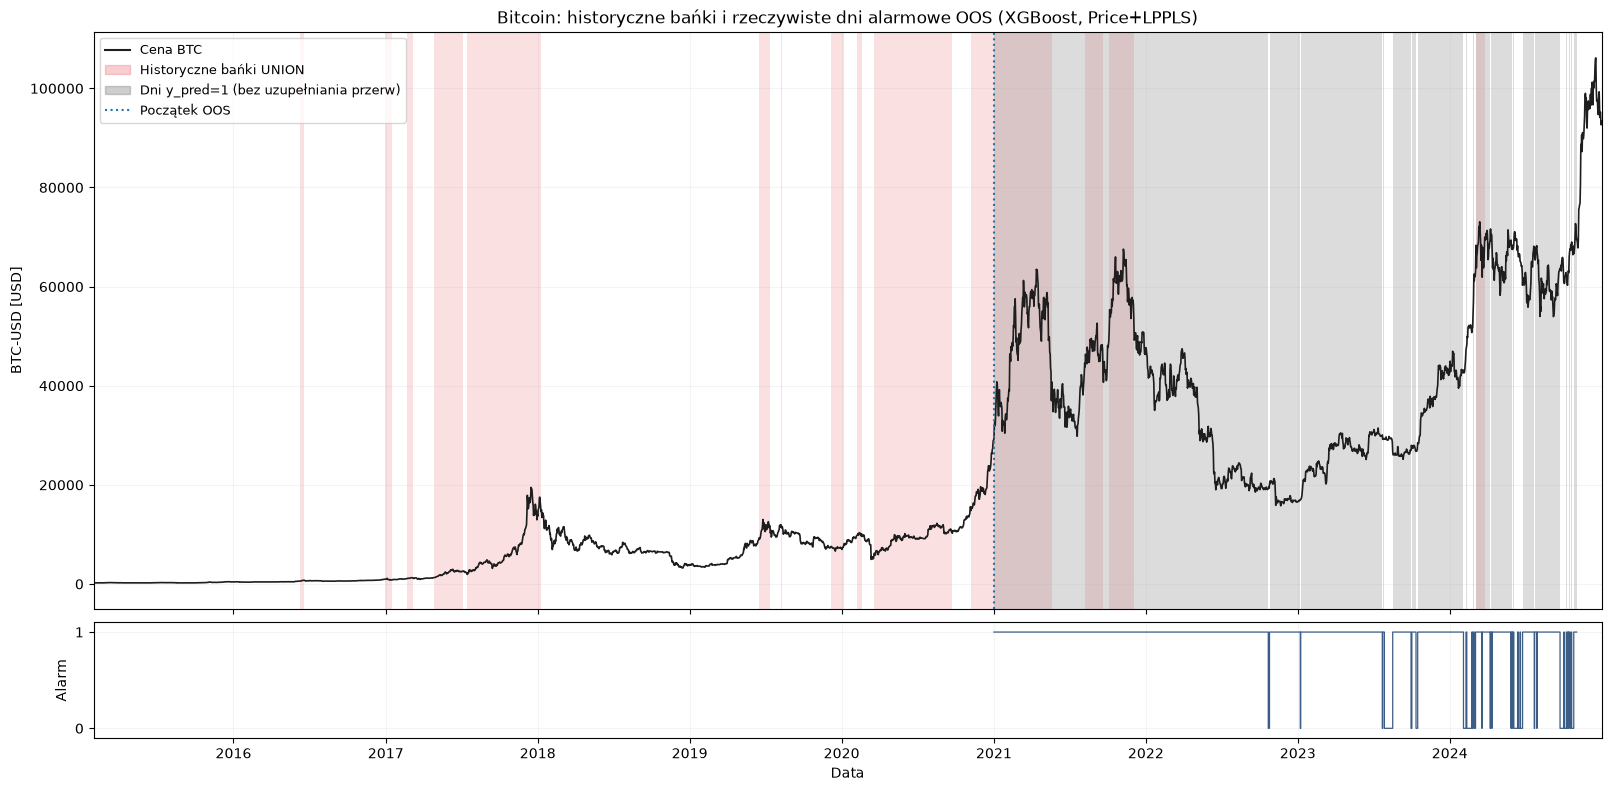

In [8]:
def plot_price_bubbles_and_real_alarms(price_df, union_df, active_intervals,
                                       daily_pred, destination, model_name, feature_name, log_scale=False):
    fig, (ax, ax_state) = plt.subplots(
        2, 1, figsize=(16,7.8), sharex=True, layout='constrained',
        gridspec_kw={'height_ratios':[5,1]}
    )
    ax.plot(price_df.date, price_df.price, lw=1.2, color='#1e1e1e')
    for row in union_df.itertuples(index=False):
        ax.axvspan(row.start, row.end+pd.Timedelta(days=1), color='#ed737b',alpha=.22,lw=0)
    for row in active_intervals.itertuples(index=False):
        ax.axvspan(row.start, row.end+pd.Timedelta(days=1), color='#6d6d6d',alpha=.24,lw=0)

    ax.axvline(daily_pred.date.min(), color='#2475aa',linestyle=':',lw=1.5)
    ax.set_xlim(price_df.date.min(), price_df.date.max())
    ax.set_ylabel('BTC-USD [USD]')
    if log_scale:
        ax.set_yscale('log')
    ax.grid(alpha=.13)
    ax.set_title(f'Bitcoin: historyczne bańki i rzeczywiste dni alarmowe OOS ({model_name}, {feature_name})')
    ax.legend(handles=[Line2D([0],[0],color='#1e1e1e',label='Cena BTC'),
                       Patch(color='#ed737b',alpha=.35,label='Historyczne bańki UNION'),
                       Patch(color='#6d6d6d',alpha=.33,label='Dni y_pred=1 (bez uzupełniania przerw)'),
                       Line2D([0],[0],color='#2475aa',linestyle=':',label='Początek OOS')],
              loc='upper left', fontsize=9)

    # Dolny panel: rzeczywiste, pojedyncze dni (w tym zera)
    ax_state.step(daily_pred.date, daily_pred.y_pred.astype(int), where='post',
                  color='#3b5d86',lw=0.9)
    ax_state.set_ylim(-.1,1.1)
    ax_state.set_yticks([0,1])
    ax_state.set_ylabel('Alarm')
    ax_state.set_xlabel('Data')
    ax_state.grid(alpha=.13)
    ax_state.xaxis.set_major_locator(mdates.YearLocator())
    ax_state.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
    fig.savefig(destination,dpi=200,bbox_inches='tight')
    plt.show()

plot_key = (PLOT_DROP,PLOT_HORIZON,PLOT_MODEL,PLOT_FEATURE_GROUP)
if plot_key not in results_cache:
    warnings.warn('Brak wskazanego wariantu — rysuję pierwszy dostępny wariant.')
    plot_key = next(iter(results_cache))
D,H,plot_model,plot_group = plot_key
view = results_cache[plot_key]
plot_price_bubbles_and_real_alarms(
    prices, union, view['active_intervals'], view['daily'],
    OUT/'10_05_cena_BTC_historyczne_banki_i_FAKTYCZNE_alarmy.png',
    plot_model, plot_group, LOG_PRICE_SCALE
)

## 9. Wykres zdarzeń spadkowych: szare pasma tylko na dniach z alarmem

Czerwone znaczniki to **zdarzenia drawdown**, nie `UNION` ani momenty końca okna etykiety z notatnika 07. Kolor zielony przy znaczniku oznacza zdarzenie z nowym, wcześniejszym ostrzeżeniem (według reguły jeden-do-jednego).

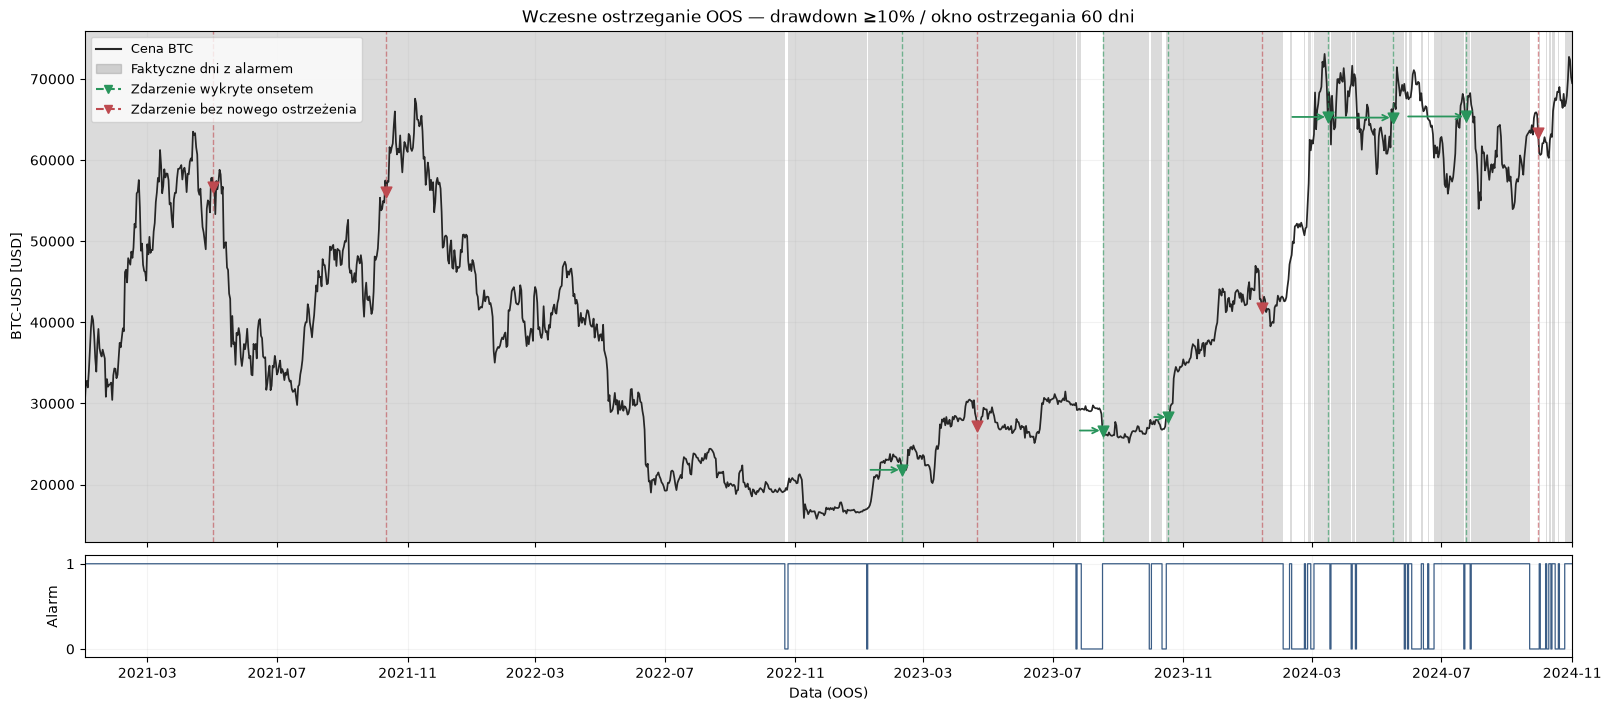

,event_id,event_date,eligible,active_before_event,detected_by_onset,first_onset_date,lead_time_days
0,DROP10_019,2021-02-23,False,False,True,2021-01-01,53.0
1,DROP10_020,2021-05-02,True,True,False,NaT,NaN
2,DROP10_021,2021-10-12,True,True,False,NaT,NaN
3,DROP10_022,2023-02-09,True,True,True,2023-01-08,32.0
4,DROP10_023,2023-04-21,True,True,False,NaT,NaN
5,DROP10_024,2023-08-17,True,True,True,2023-07-24,24.0
6,DROP10_025,2023-10-18,True,True,True,2023-10-02,16.0
7,DROP10_026,2024-01-14,True,True,False,NaT,NaN
8,DROP10_027,2024-03-16,True,True,True,2024-02-09,36.0
9,DROP10_028,2024-05-16,True,True,True,2024-03-19,58.0


In [9]:
def plot_event_timeline(price_df, events, active_intervals, daily_pred, destination, H, D):
    t0,t1=daily_pred.date.min(),daily_pred.date.max()
    pp=price_df.loc[price_df.date.between(t0,t1)]
    fig,(ax,ax_state)=plt.subplots(2,1,figsize=(16,7),sharex=True,layout='constrained',
                                   gridspec_kw={'height_ratios':[5,1]})
    ax.plot(pp.date,pp.price,lw=1.25,color='#262626')
    for row in active_intervals.itertuples(index=False):
        ax.axvspan(row.start, row.end+pd.Timedelta(days=1),color='#808080',alpha=.28,lw=0)
    ev=events.loc[events['eligible'] & events.event_date.between(t0,t1)]
    for row in ev.itertuples(index=False):
        col='#29955c' if row.detected_by_onset else '#be4a50'
        ax.axvline(row.event_date,linestyle='--',color=col,lw=1,alpha=.6)
        ax.scatter([row.event_date],[row.price_at_crossing],marker='v',s=60,color=col,zorder=4)
        if row.detected_by_onset and pd.notna(row.first_onset_date):
            ax.annotate('',xy=(row.event_date,row.price_at_crossing),
                        xytext=(row.first_onset_date,row.price_at_crossing),
                        arrowprops={'arrowstyle':'->','color':'#29955c','lw':1.3},clip_on=True)
    ax.set_title(f'Wczesne ostrzeganie OOS — drawdown ≥{D}% / okno ostrzegania {H} dni')
    ax.set_ylabel('BTC-USD [USD]')
    ax.set_xlim(t0,t1)
    ax.grid(alpha=.16)
    ax.legend(handles=[Line2D([0],[0],color='#262626',label='Cena BTC'),
                       Patch(color='#808080',alpha=.33,label='Faktyczne dni z alarmem'),
                       Line2D([0],[0],marker='v',color='#29955c',linestyle='--',label='Zdarzenie wykryte onsetem'),
                       Line2D([0],[0],marker='v',color='#be4a50',linestyle='--',label='Zdarzenie bez nowego ostrzeżenia')],
              fontsize=9,loc='upper left')
    ax_state.step(daily_pred.date,daily_pred.y_pred.astype(int),where='post',color='#3b5d86',lw=0.9)
    ax_state.set_ylim(-.1,1.1)
    ax_state.set_yticks([0,1]);ax_state.set_ylabel('Alarm');ax_state.set_xlabel('Data (OOS)')
    ax_state.grid(alpha=.14)
    ax_state.xaxis.set_major_locator(mdates.MonthLocator(interval=4))
    ax_state.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
    fig.savefig(destination,dpi=200,bbox_inches='tight')
    plt.show()

plot_event_timeline(
    prices,view['events'],view['active_intervals'],view['daily'],
    OUT/'10_06_cena_BTC_zdarzenia_i_FAKTYCZNE_alarmy.png',H,D
)
display(view['events'][['event_id','event_date','eligible','active_before_event',
                        'detected_by_onset','first_onset_date','lead_time_days']])

## 10. Porównanie modeli: event recall kontra liczba nowych, fałszywych ostrzeżeń

Dodatkowe metryki `time_in_alarm` i `event_recall_active` trzeba czytać **razem**: system stale alarmujący może mieć aktywny alarm przed wieloma zdarzeniami, ale jego zdolność do rozróżniania sytuacji wysokiego ryzyka pozostaje ograniczona.

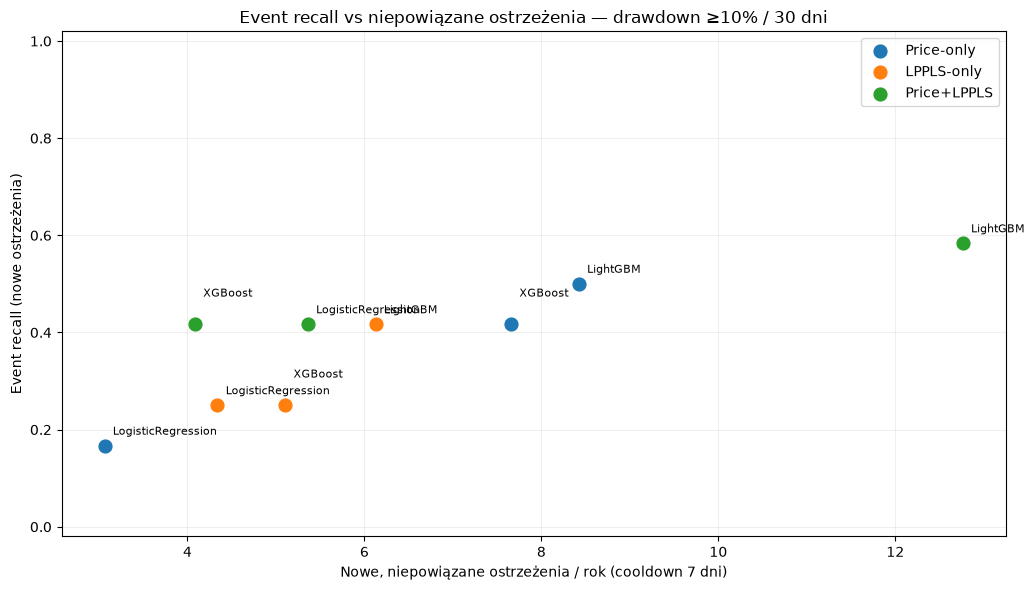

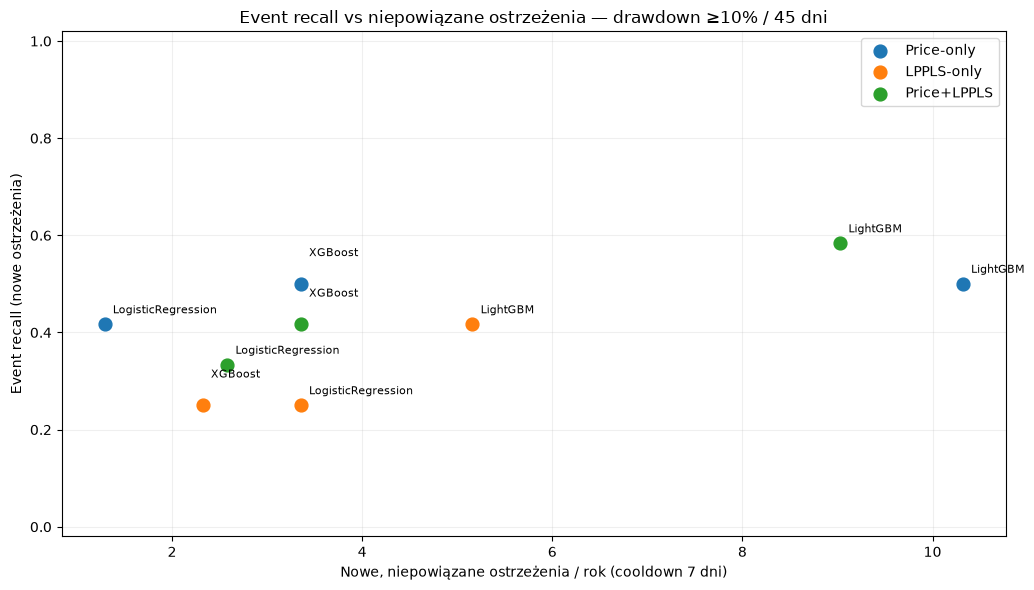

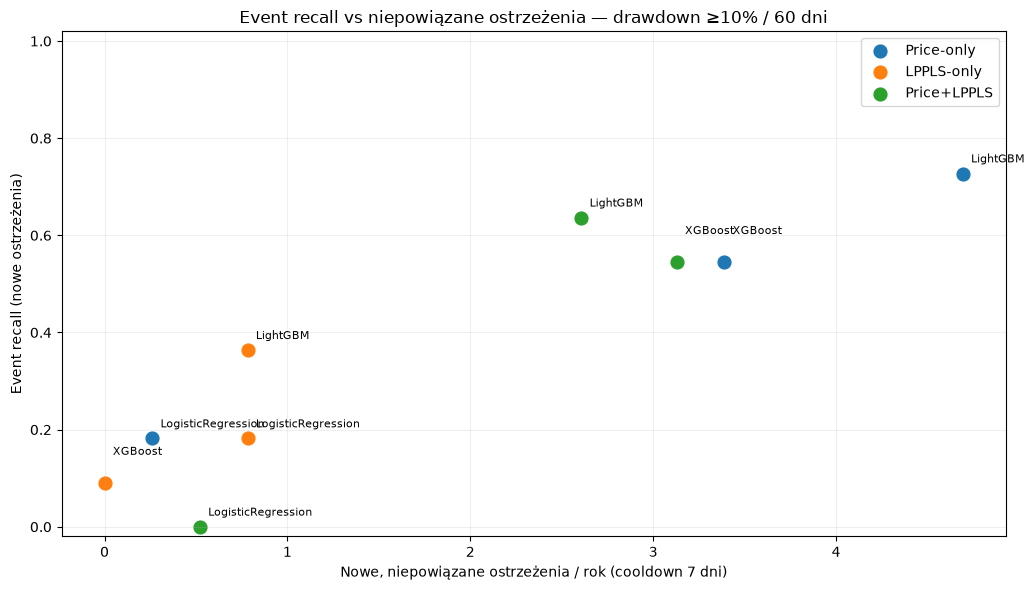

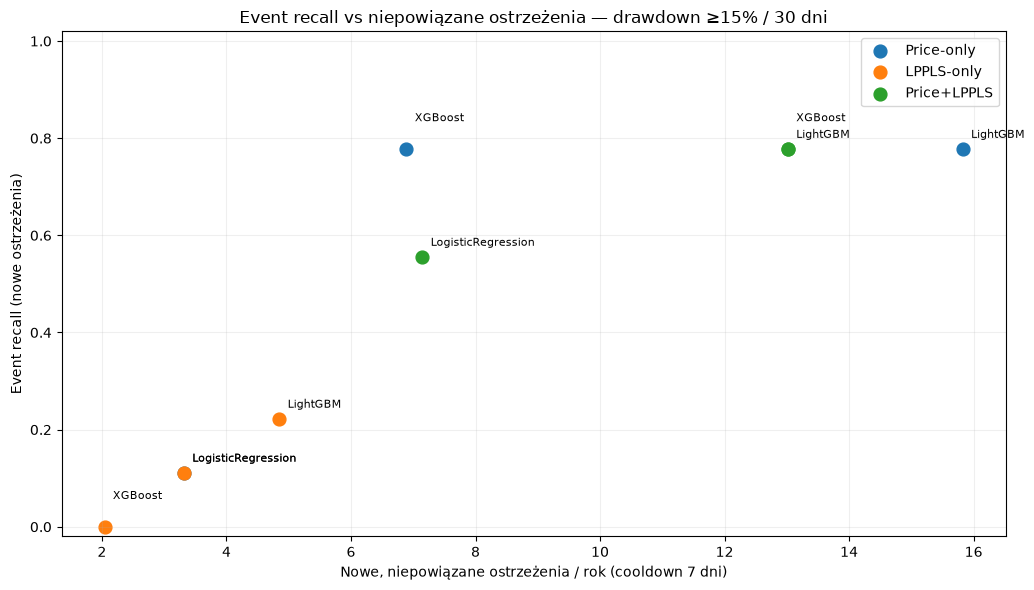

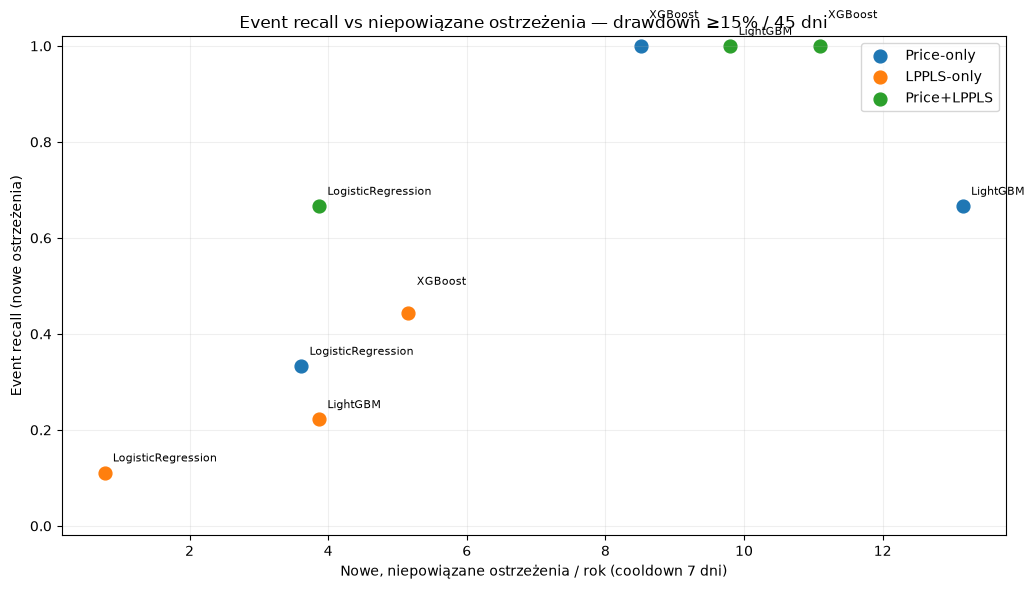

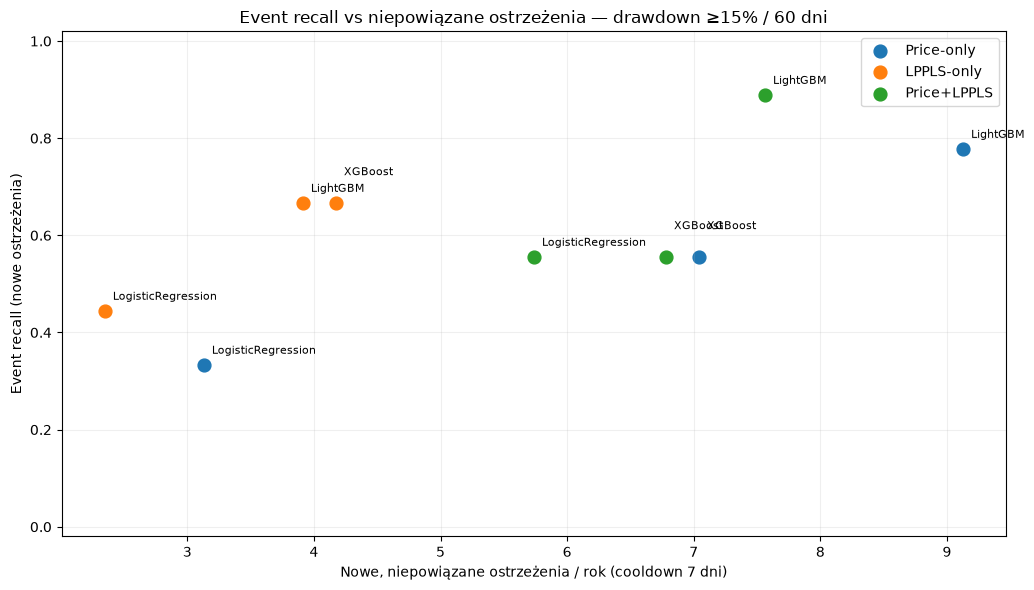

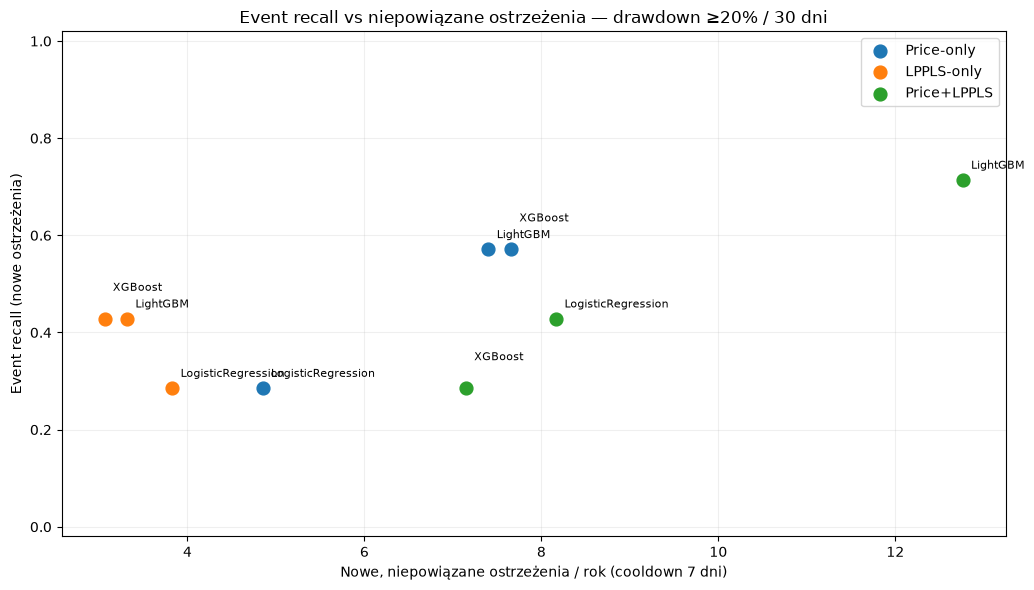

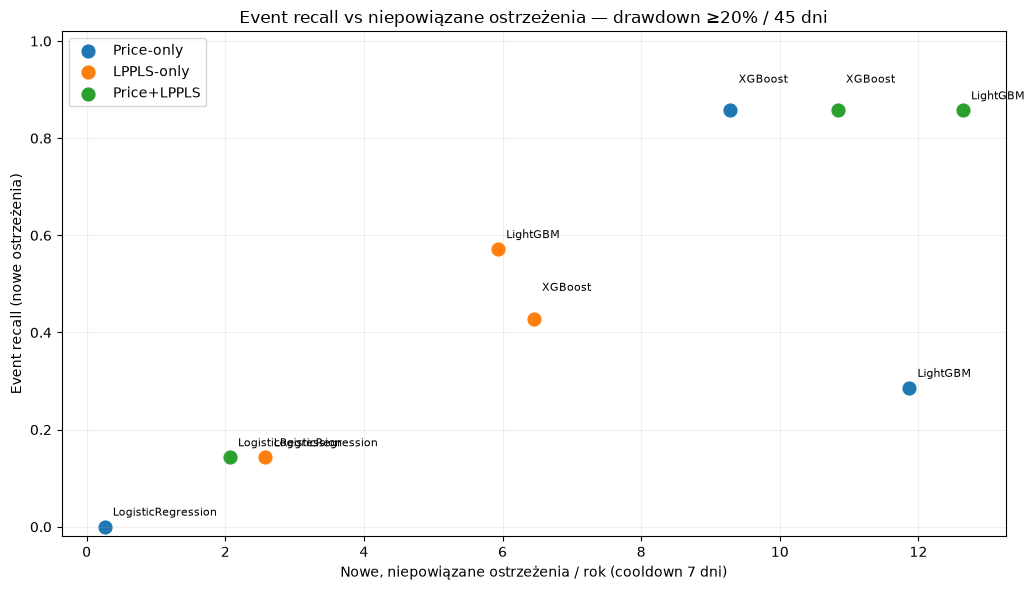

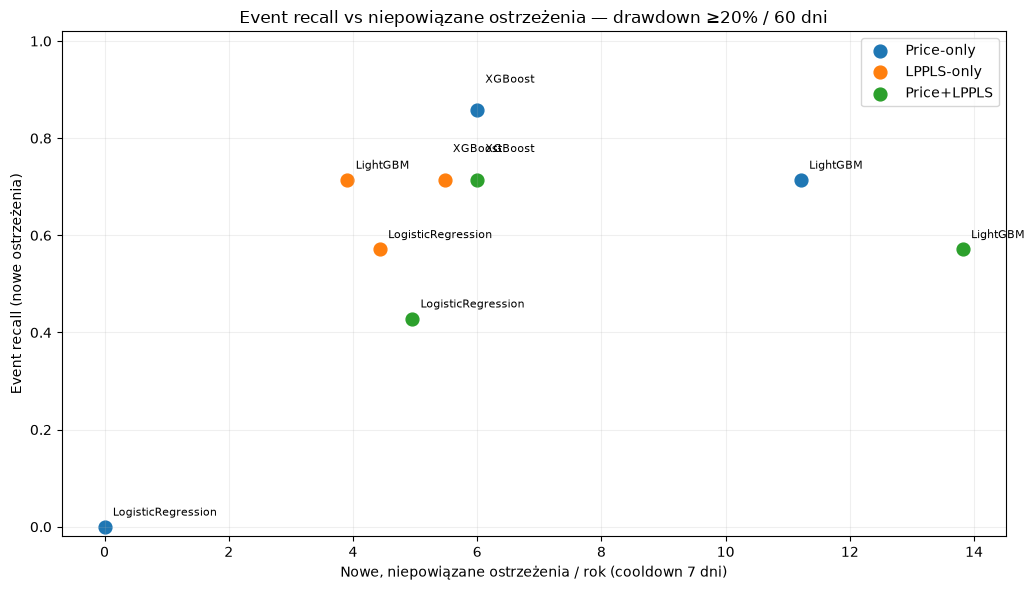

In [10]:
for D,H in TARGET_CONFIGS:
    sub=summary.loc[summary.drop_pct.eq(D) & summary.horizon.eq(H)].copy()
    if sub.empty:
        continue
    fig,ax=plt.subplots(figsize=(10.5,6))
    for group,df_group in sub.groupby('feature_group',sort=False):
        ax.scatter(df_group.false_warnings_per_year,df_group.event_recall_onset,s=85,label=group)
        for k,row in enumerate(df_group.itertuples(index=False)):
            if pd.notna(row.event_recall_onset) and pd.notna(row.false_warnings_per_year):
                ax.annotate(row.model,(row.false_warnings_per_year,row.event_recall_onset),
                            textcoords='offset points',xytext=(6,8+12*(k%2)),fontsize=8)
    ax.set_xlabel('Nowe, niepowiązane ostrzeżenia / rok (cooldown 7 dni)')
    ax.set_ylabel('Event recall (nowe ostrzeżenia)')
    ax.set_ylim(-.02,1.02); ax.grid(alpha=.2)
    ax.set_title(f'Event recall vs niepowiązane ostrzeżenia — drawdown ≥{D}% / {H} dni')
    ax.legend(loc='best')
    fig.tight_layout()
    fig.savefig(OUT/f'10_07_event_recall_vs_falszywe_ostrzezenia_{D}_{H}.png',dpi=180)
    plt.show()

## 11. Raport kontroli i interpretacja

Wyniki zapisano w `wyniki_event_based_10_poprawione/`. Przed publikacją:

1. Rozdzielaj metryki z **nowych ostrzeżeń** i z **ciągłego stanu alarmowego**.
2. Pamiętaj, że `false_warning_onsets` to brak późniejszego zdarzenia według naszej **konkretnej definicji drawdown**, a nie bezspornie fałszywy alarm ekonomiczny.
3. Oceń wrażliwość na `WARNING_COOLDOWN_DAYS` (0/3/7/14), `EVENT_MIN_SEPARATION_DAYS` (30/60/90), `PEAK_LOOKBACK_DAYS` (90/180/365).
4. Porównanie z klasycznym `drop_D_hH` wymaga osobnego protokołu — oba cele nie są równoważne.
5. Wyniki dla 2021–2024 były już wielokrotnie eksplorowane; konieczny jest przyszły niezależny test lub wyraźne oznaczenie ich jako eksploracyjnych.

In [11]:
check = summary[['drop_pct','horizon','model','feature_group',
                 'prediction_days','positive_days','time_in_alarm',
                 'active_intervals','warning_onsets_after_cooldown',
                 'evaluable_events','event_recall_onset','event_recall_active',
                 'evaluable_warnings','false_warning_onsets','false_warnings_per_year']]
display(check.round(3))
print('Zapisano pliki w:', OUT.resolve())
print('Ważne: przy wysokim time_in_alarm wykres pozostanie szary przez większość okresu,')
print('ale będzie to prawdziwy stan y_pred — bez sztucznego łączenia przerw.')

,drop_pct,horizon,model,feature_group,prediction_days,positive_days,time_in_alarm,active_intervals,warning_onsets_after_cooldown,evaluable_events,event_recall_onset,event_recall_active,evaluable_warnings,false_warning_onsets,false_warnings_per_year
0,10,30,LogisticRegression,Price-only,1431,1347,0.941,18,14,12,0.167,1.000,14,12,3.063
1,10,30,LogisticRegression,LPPLS-only,1431,1114,0.778,29,20,12,0.250,0.833,20,17,4.339
2,10,30,LogisticRegression,Price+LPPLS,1431,1291,0.902,35,26,12,0.417,1.000,26,21,5.360
3,10,30,XGBoost,Price-only,1431,1144,0.799,50,36,12,0.417,1.000,36,30,7.657
4,10,30,XGBoost,LPPLS-only,1431,1116,0.780,34,23,12,0.250,0.833,23,20,5.105
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
76,20,60,XGBoost,LPPLS-only,1401,1033,0.737,43,27,7,0.714,1.000,27,21,5.475
77,20,60,XGBoost,Price+LPPLS,1401,924,0.660,40,29,7,0.714,0.714,29,23,5.996
78,20,60,LightGBM,Price-only,1401,542,0.387,68,49,7,0.714,0.714,49,43,11.210
79,20,60,LightGBM,LPPLS-only,1401,699,0.499,36,21,7,0.714,0.714,21,15,3.911


Zapisano pliki w: C:\Users\cynar\Desktop\projects\article\10_wyniki_event_based
Ważne: przy wysokim time_in_alarm wykres pozostanie szary przez większość okresu,
ale będzie to prawdziwy stan y_pred — bez sztucznego łączenia przerw.
